# Avrami with unkown parameters
This example is similar at 1, but discovering Ea and A.
The problem here is the scaling; to work need to scale up of 10^12.

In [27]:
import math
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import functools

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class DiscoveryNet(nn.Module):
    def __init__(self, input_dim, output_dim, n_units=100, epochs=1000, loss = nn.MSELoss(), lr=1e-3, loss2=None, loss2_weight=0.1, patience=0) -> None:
        super().__init__()

        self.input_dim = input_dim
        self.output_dim = output_dim
        self.epochs = epochs
        self.loss = loss
        self.loss2 = loss2
        self.loss2_weight = loss2_weight
        self.lr = lr 
        self.n_units = n_units
        self.patience = patience
    
        self.layers = nn.Sequential(
        nn.Linear(input_dim, self.n_units),
        nn.ReLU(),
        nn.Linear(self.n_units,self.n_units),
        nn.ReLU(),
        nn.Linear(self.n_units,self.n_units),
        nn.ReLU(),
        nn.Linear(self.n_units,self.n_units),
        nn.ReLU(),
        )
        self.out = nn.Linear(self.n_units, output_dim)
    
    def forward(self, x):
        h = self.layers(x)
        out = self.out(h)
        
        return out

    def fit(self, X, y, scaler=None):
        Xt = np_to_tensor(X)
        yt = np_to_tensor(y)

        optimiser = optim.Adam(self.parameters(), lr=self.lr)
        self.train()
        losses = []
        data_losses = []
        physic_losses = []
        for ep in range(self.epochs):
            optimiser.zero_grad()
            outputs = self.forward(Xt)

            d = outputs[:, 0].reshape(-1, 1)
            # d = scaler.inverse_transform(d).type(torch.float32) if scaler else d

            data_loss = self.loss(yt, d)
            if self.loss2:
                physic_loss = self.loss2_weight * self.loss2(self)
                loss = data_loss + physic_loss
                physic_losses.append(physic_loss.item())
            else:
                loss = data_loss
            data_losses.append(data_loss.item())

            loss.backward()
            optimiser.step()
            losses.append(loss.item())
            if ep % int(self.epochs / 10) == 0:
                if physic_losses:
                    physic_loss_avg = np.mean(physic_losses).item()
                else:
                    physic_loss_avg = 0

                print(f"Epoch {ep}/{self.epochs}, loss: {np.mean(losses).item():.6f} - data_loss: {np.mean(data_losses).item():.6f} - physic_loss: {physic_loss_avg:.6f}")
        return losses

    def predict(self, X):
        self.eval()
        out = self.forward(np_to_tensor(X))
        return out.detach().cpu().numpy()

def np_to_tensor(x):
    if isinstance(x, torch.Tensor) and x.device == DEVICE:
        return x
    elif isinstance(x, torch.Tensor):
        return x.to(DEVICE)
    elif isinstance(x, list):
        x = np.array(x)
    
    n_samples = len(x)
    return torch.from_numpy(x).to(torch.float).to(DEVICE).reshape(n_samples, -1)

In [28]:
class TorchMinMaxScaler(nn.Module):
    def __init__(self):
        super().__init__()
        self.min_val = torch.tensor(0, dtype=torch.float32, device=DEVICE)
        self.max_val = torch.tensor(1, dtype=torch.float32, device=DEVICE)

    def fit_transform(self, data):
        # Compute min and max values from the data
        if not isinstance(data, torch.Tensor):
            data = torch.from_numpy(data)
        self.min_val = torch.min(data, dim=0)[0].to(device=DEVICE)
        self.max_val = torch.max(data, dim=0)[0].to(device=DEVICE)
        return self.transform(data)
    
    def transform(self, x):
        prev = None
        if not isinstance(x, torch.Tensor):
            x = torch.from_numpy(x).to(device=DEVICE)
        if x.device != DEVICE:
            prev  = x.device
            x = x.to(device=DEVICE)
        # Scale x to the range [0, 1]
        scaled = (x - self.min_val) / (self.max_val - self.min_val)
        if prev != DEVICE:
            scaled = scaled.to(device=prev)
        return scaled.type(torch.float32)
    
    def inverse_transform(self, x_scaled):
        # Inverse scaling: bring x_scaled back to original range
        return x_scaled * (self.max_val - self.min_val) + self.min_val

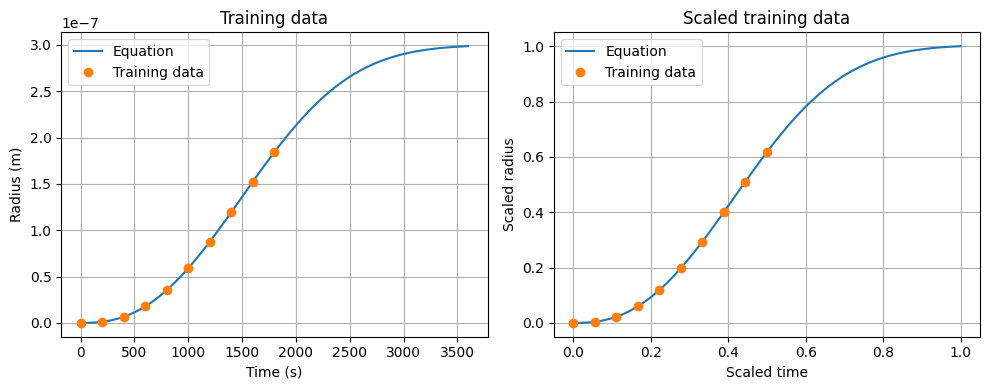

In [29]:
import numpy as np
import functools
import matplotlib.pyplot as plt

def avrami_law(t,Ea,R,T,A,n,r_max):
    K = A * np.exp(-Ea / (R * T))
    d = r_max * (1 - np.exp(-K * t**n))

    return d

np.random.seed(10)
A = 5e-3              # Increased to speed up transformation
Ea = 60000           # Lowered to increase reaction rate
T = 535             # Higher temp for faster growth
r_max = 30e-8       # Max radius in meters (30 nm)
n = 2.5
R = 8.314
# Time array
gt_times_X = np.linspace(0, 3600, 100)
eq = functools.partial(avrami_law, Ea=Ea, A=A, T=T, r_max=r_max, n=n, R=R)
gt_d_Y = eq(gt_times_X) # * 1e9

# Training data with noise
N_POINTS = 10
train_times_X = np.linspace(0, 3600//2, N_POINTS)
noise_std = 0.001 * r_max
train_d_Y = (eq(train_times_X) + noise_std * np.random.randn(N_POINTS)) # * 1e9


# Scale data
scaler_X = TorchMinMaxScaler()
scaler_Y = TorchMinMaxScaler()

# Fit and transform the training data
eq_times_X_scaled = scaler_X.fit_transform(gt_times_X.reshape(-1, 1)).type(torch.float32)
eq_d_Y_scaled = scaler_Y.fit_transform(gt_d_Y.reshape(-1, 1)).type(torch.float32)

# Transform test data using the already fitted scalers
train_times_X_scaled = scaler_X.transform(train_times_X.reshape(-1, 1)).type(torch.float32)
train_d_Y_scaled = scaler_Y.transform(train_d_Y.reshape(-1, 1)).type(torch.float32)


# Plot
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(gt_times_X, gt_d_Y, label="Equation")
plt.plot(train_times_X, train_d_Y , 'o', label="Training data")
# noisy data
plt.grid()
plt.legend()
plt.title("Training data")
plt.xlabel("Time (s)")
plt.ylabel("Radius (m)")
plt.subplot(1, 2, 2)
plt.plot(eq_times_X_scaled, eq_d_Y_scaled, label="Equation")
plt.plot(train_times_X_scaled.cpu().numpy(), train_d_Y_scaled.cpu().numpy() , 'o', label="Training data")
plt.grid()
plt.legend()
plt.title("Scaled training data")
plt.xlabel("Scaled time")
plt.ylabel("Scaled radius")
plt.tight_layout()
plt.show(block=False)

In [ ]:

vanilla = DiscoveryNet(1, 3, loss2=None, loss2_weight=1, epochs=30000, lr=1e-4).to(DEVICE)
losses = vanilla.fit(train_times_X_scaled.to(DEVICE), train_d_Y_scaled.to(DEVICE), scaler_Y)
plt.plot(losses)
plt.yscale('log')

Epoch 0/30000, loss: 0.097558 - data_loss: 0.097558 - physic_loss: 0.000000
Epoch 3000/30000, loss: 0.001838 - data_loss: 0.001838 - physic_loss: 0.000000
Epoch 6000/30000, loss: 0.000919 - data_loss: 0.000919 - physic_loss: 0.000000
Epoch 9000/30000, loss: 0.000613 - data_loss: 0.000613 - physic_loss: 0.000000
Epoch 12000/30000, loss: 0.000460 - data_loss: 0.000460 - physic_loss: 0.000000
Epoch 15000/30000, loss: 0.000368 - data_loss: 0.000368 - physic_loss: 0.000000
Epoch 18000/30000, loss: 0.000307 - data_loss: 0.000307 - physic_loss: 0.000000
Epoch 21000/30000, loss: 0.000263 - data_loss: 0.000263 - physic_loss: 0.000000
Epoch 24000/30000, loss: 0.000230 - data_loss: 0.000230 - physic_loss: 0.000000
Epoch 27000/30000, loss: 0.000204 - data_loss: 0.000204 - physic_loss: 0.000000


[0.09755777567625046,
 0.09580361843109131,
 0.09410493820905685,
 0.09246331453323364,
 0.09084627777338028,
 0.08924715965986252,
 0.08766764402389526,
 0.08610343933105469,
 0.08456027507781982,
 0.08303668349981308,
 0.08153089135885239,
 0.08004371076822281,
 0.07857725769281387,
 0.07713384181261063,
 0.07570832222700119,
 0.07430755347013474,
 0.07294394820928574,
 0.071632519364357,
 0.0703624039888382,
 0.06911956518888474,
 0.06790129095315933,
 0.06669621914625168,
 0.06551069021224976,
 0.06434377282857895,
 0.06319376826286316,
 0.06205989792943001,
 0.06095355749130249,
 0.059889353811740875,
 0.05884679779410362,
 0.05782708153128624,
 0.05682689696550369,
 0.0558486245572567,
 0.054886914789676666,
 0.05394173413515091,
 0.053010810166597366,
 0.05209827050566673,
 0.05121155455708504,
 0.05035049840807915,
 0.04951345548033714,
 0.04870106279850006,
 0.0479063019156456,
 0.04712929576635361,
 0.046371955424547195,
 0.04563158378005028,
 0.04491070285439491,
 0.04420834

Epoch 0/150000, loss: 0.129136 - data_loss: 0.101565 - physic_loss: 0.027571
Epoch 15000/150000, loss: 0.016863 - data_loss: 0.001546 - physic_loss: 0.015316
Epoch 30000/150000, loss: 0.016732 - data_loss: 0.000797 - physic_loss: 0.015935
Epoch 45000/150000, loss: 0.014234 - data_loss: 0.000539 - physic_loss: 0.013695
Epoch 60000/150000, loss: 0.011550 - data_loss: 0.000409 - physic_loss: 0.011141
Epoch 75000/150000, loss: 0.009842 - data_loss: 0.000329 - physic_loss: 0.009513
Epoch 90000/150000, loss: 0.008749 - data_loss: 0.000277 - physic_loss: 0.008472
Epoch 105000/150000, loss: 0.007870 - data_loss: 0.000239 - physic_loss: 0.007632
Epoch 120000/150000, loss: 0.007242 - data_loss: 0.000210 - physic_loss: 0.007032
Epoch 135000/150000, loss: 0.006752 - data_loss: 0.000187 - physic_loss: 0.006564


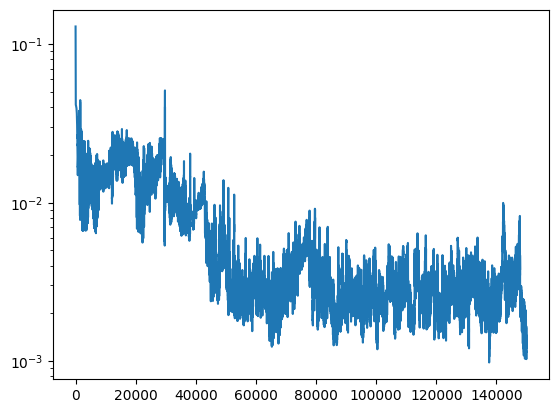

In [ ]:


def set_seed(seed):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    

def physics_loss(model: torch.nn.Module):
    global PHYSICAL_LOSS_SCALING_FACTOR

    # Create time input for PINN
    ts = torch.linspace(0, 3600, steps=100, dtype=torch.float32).view(-1, 1).to(DEVICE).requires_grad_(True)
    ts_scaled = scaler_X.transform(ts)

    # Predict radius
    out = model(ts_scaled)
    d, Ea_net, A_net = out[:, 0], out[:, 1], out[:, 2]  # [-1, 1] [0, 1]
    d = scaler_Y.inverse_transform(d)
    
    Ea = torch.nn.functional.softplus(Ea_net) * 1e5
    A = torch.nn.functional.softplus(A_net) * 1e-3
    # Ea = Ea_net * 1e5 
    # A = A_net * 1e-3

    # Compute model's derivative wrt time
    dd = torch.autograd.grad(
        d, ts, 
        grad_outputs=torch.ones_like(d), 
        create_graph=True
    )[0]

    # Compute K
    K = A * torch.exp(-Ea / (R * T))
    # Theoretical Avrami derivative
    derived_eq = r_max * K * n * ts.pow(n - 1) * torch.exp(-K * ts.pow(n))

    pde_residual = dd - derived_eq
    # pde_residual = pde_residual * 1e12
    if PHYSICAL_LOSS_SCALING_FACTOR is None:
        # # Get the maximum residual value as a float
        # val = torch.max(pde_residual).item()
        # # Compute the order-of-magnitude exponent. For a value like 5.23e-6,
        # # math.log10(val) ≈ -5.28, and floor(-5.28) gives -6.
        # exponent = -math.floor(math.log10(val))
        # # Set the scaling factor as 10 raised to the computed exponent.
        # PHYSICAL_LOSS_SCALING_FACTOR = 10 ** exponent

        PHYSICAL_LOSS_SCALING_FACTOR = 1e10

    pde_residual = pde_residual * PHYSICAL_LOSS_SCALING_FACTOR
    
    physical_loss = torch.mean(pde_residual**2)
    return physical_loss

# PHYSICAL_LOSS_SCALING_FACTOR = 1e-12
PHYSICAL_LOSS_SCALING_FACTOR = None

set_seed(0)
scaler_X = scaler_X.to(DEVICE)
scaler_Y = scaler_Y.to(DEVICE)
curr_train_times_X = train_times_X_scaled.to(DEVICE)
curr_train_d_Y = train_d_Y_scaled.to(DEVICE)


# net = DiscoveryNet(1, 3, loss2=physics_loss, loss2_weight=1, epochs=150000, lr=1e-4).to(DEVICE)
net = DiscoveryNet(1, 3, loss2=physics_loss, loss2_weight=1, epochs=150000, lr=1e-4).to(DEVICE)
losses = net.fit(curr_train_times_X, curr_train_d_Y, scaler_Y)

plt.plot(losses)
plt.yscale('log')

Predicted A: 0.0006225091055966914, Expected A: 0.005
Predicted Ea: 50803.953125, Expected Ea: 60000


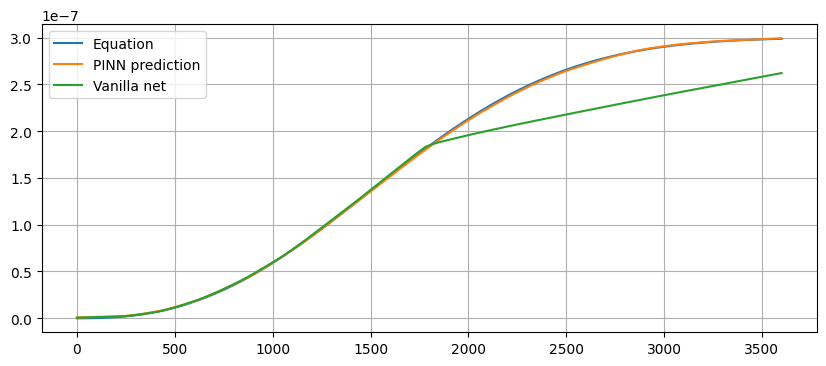

In [33]:
# plot the prediction on gt data

pred = net.predict(eq_times_X_scaled)
pred = torch.tensor(pred, dtype=torch.float32, device=DEVICE)
d, Ea_net, A_net = pred[:, 0], pred[:, 1], pred[:, 2]
d = scaler_Y.inverse_transform(d)
d = d.cpu().numpy()
Ea_net = Ea_net.cpu()
A_net = A_net.cpu()

# expected:
A_expected = 5e-3              # Increased to speed up transformation
Ea_expected = 60000           # Lowered to increase reaction rate

Ea = torch.nn.functional.softplus(Ea_net) * 1e5
A = torch.nn.functional.softplus(A_net) * 1e-3

print(f"Predicted A: {A.mean().item()}, Expected A: {A_expected}")
print(f"Predicted Ea: {Ea.mean().item()}, Expected Ea: {Ea_expected}")

vanilla_pred = vanilla.predict(eq_times_X_scaled)
vanilla_pred = torch.tensor(vanilla_pred, dtype=torch.float32, device=DEVICE)
vanilla_d = vanilla_pred[:, 0]
vanilla_d = scaler_Y.inverse_transform(vanilla_d)
vanilla_d = vanilla_d.cpu().numpy()
plt.figure(figsize=(10, 4))
# plt.subplot(1, 2, 1)
plt.plot(gt_times_X, gt_d_Y, label="Equation")
plt.plot(gt_times_X, d, label="PINN prediction")
plt.plot(gt_times_X, vanilla_d, label="Vanilla net")
plt.grid()
plt.legend()
plt.show()